# 05 Age normalization of views

In [1]:
"""Can daily snapshots give a way to compare videos of different ages? Settings pin the snapshot range so the
numbers are reproducible. Shorts = duration <= 60 s (the project's definition). Size tiers by channel subscribers."""
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from google.cloud import bigquery
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

sys.path.insert(0, os.path.abspath("../src"))
import config

SNAPSHOT_START = "2026-10-15"
SNAPSHOT_END = "2026-11-04"
DAILY_START = "2026-10-21"
SHORTS_MAX_SECONDS = 60
TIER_EDGES = [0, 2e6, 1e7, 1e12]
TIER_LABELS = ["<2M subs", "2-10M subs", ">=10M subs"]
RATE_BINS = [0, 1, 2, 4, 7, 14, 30, 60, 120, 240, 400]
KNOTS = [1, 2, 3, 4, 5.5, 7, 10, 14, 20, 30, 45, 60, 90, 120, 180, 240, 300, 400]
ANCHOR_AGE = 1
MIN_AGE_DAYS = 1
REF_AGES = [7, 30]
EVAL_MIN_HORIZON = 7
EVAL_BANDS = [1, 7, 30, 120, 400]
N_BOOT = 200
N_SPLITS = 10
SHRINK_GRID = [0, 2, 5, 10, 20, 50, 1e9]
SEED = 585
GENRE_NAMES = {"24": "Entertainment", "22": "People & Blogs", "17": "Sports", "27": "Education",
               "28": "Science & Tech", "23": "Comedy", "25": "News & Politics", "20": "Gaming", "26": "Howto & Style"}
COLORS = {"long": "#2a78d6", "short": "#eb6834", TIER_LABELS[0]: "#2a78d6", TIER_LABELS[1]: "#eb6834",
          TIER_LABELS[2]: "#1baf7a", "gray": "#8a8a85"}
FIG_DIR = "../docs/figures"
ANALYSIS_DIR = "../data/analysis"
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(ANALYSIS_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
rng = np.random.default_rng(SEED)
client = bigquery.Client(project=config.GCP_PROJECT_ID, location=config.BQ_LOCATION)

## Load the snapshot panel

In [2]:
"""One row per video per snapshot day, joined to video duration/category and channel subscribers.
Rows whose channel is no longer in `channels` (one leftover video) are dropped."""
df_panel = client.query(f"""
SELECT s.snapshot_date, s.snapshot_at, s.video_id, s.channel_id, s.published_at, s.age_days,
       s.view_count, s.like_count, s.comment_count, s.is_available,
       v.duration_seconds, v.snippet_categoryId AS category_id,
       SAFE_CAST(c.statistics_subscriberCount AS INT64) AS subscribers, c.snippet_title AS channel_title
FROM youtube.video_daily_snapshots s
JOIN youtube.videos v ON v.id = s.video_id
JOIN youtube.channels c ON c.id = s.channel_id
WHERE s.snapshot_date BETWEEN '{SNAPSHOT_START}' AND '{SNAPSHOT_END}'
""").to_dataframe()
df_panel = df_panel.sort_values(["video_id", "snapshot_at"]).reset_index(drop=True)
df_panel["format"] = np.where(df_panel["duration_seconds"] <= SHORTS_MAX_SECONDS, "short", "long")
df_panel["tier"] = pd.cut(df_panel["subscribers"].astype(float), TIER_EDGES, labels=TIER_LABELS, right=False).astype(str)
df_panel["genre"] = df_panel["category_id"].map(GENRE_NAMES).fillna("Other")
df_panel["log_subs"] = np.log10(df_panel["subscribers"].astype(float))
df_panel["lv"] = np.log1p(df_panel["view_count"].astype(float))
df_panel["ll"] = np.log1p(df_panel["like_count"].astype(float))
print(df_panel.shape, df_panel["video_id"].nunique(), "videos", df_panel["channel_id"].nunique(), "channels")
df_videos = df_panel.drop_duplicates("video_id")
print(df_videos.groupby(["format", "tier"]).agg(videos=("video_id", "size"), channels=("channel_id", "nunique")))
print(df_videos["genre"].value_counts())

/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


(213723, 20) 13718 videos 52 channels
                   videos  channels
format tier                        
long   2-10M subs    3020        20
       <2M subs      3077        15
       >=10M subs    2614        17
short  2-10M subs    3062        19
       <2M subs       536         8
       >=10M subs    1409        14
genre
Entertainment      5198
People & Blogs     2616
Sports             2289
Education          1227
Science & Tech      763
Comedy              730
News & Politics     421
Other               182
Gaming              159
Howto & Style       133
Name: count, dtype: int64


## Data quality

In [3]:
"""Rows per day and pull time, observations per video, gaps, spacing between pulls, decreasing counts.
The 2026-10-15 seed pull ran per channel over ~15 hours; every later day is one pull time for all videos."""
print(df_panel.groupby("snapshot_date").agg(rows=("video_id", "size"), first_pull=("snapshot_at", "min"),
                                             last_pull=("snapshot_at", "max"), unavailable=("is_available", lambda x: int((~x.astype(bool)).sum()))))
df_panel["dt_prev"] = df_panel.groupby("video_id")["snapshot_at"].diff().dt.total_seconds() / 86400
df_daily = df_panel[df_panel["snapshot_date"] > pd.Timestamp(DAILY_START).date()]
print("Spacing between consecutive daily pulls (days):")
print(df_daily["dt_prev"].describe().round(3))
print("Gaps > 1.5 days inside the daily window:", (df_daily["dt_prev"] > 1.5).sum())
n_dates = df_panel[df_panel["snapshot_date"] >= pd.Timestamp(DAILY_START).date()]["snapshot_date"].nunique()
df_obs = df_panel[df_panel["snapshot_date"] >= pd.Timestamp(DAILY_START).date()].groupby("video_id").agg(
    n_obs=("snapshot_date", "size"), first_date=("snapshot_date", "min"))
df_obs["expected"] = [n_dates - (pd.Timestamp(first_date) - pd.Timestamp(DAILY_START)).days for first_date in df_obs["first_date"]]
print("Videos missing a daily snapshot after their first appearance:", (df_obs["n_obs"] < df_obs["expected"]).sum(), "of", len(df_obs))
print("Videos without the 10-15 seed row:", df_panel["video_id"].nunique() - (df_panel["snapshot_date"] == pd.Timestamp(SNAPSHOT_START).date()).sum())
for count_col in ["view_count", "like_count", "comment_count"]:
    change = df_panel.groupby("video_id")[count_col].diff()
    print(f"{count_col}: decreases {(change < 0).sum()} of {change.notna().sum()} consecutive pairs "
          f"({(change < 0).mean() * 100:.2f}%), unchanged {(change == 0).sum()}, hidden/NULL rows {df_panel[count_col].isna().sum()}")
view_drop = df_panel.groupby("video_id")["lv"].diff()
print("View decreases in log units (median, 99th pct of |drop|):", round(view_drop[view_drop < 0].abs().median(), 5),
      round(view_drop[view_drop < 0].abs().quantile(0.99), 4))
zero_view_videos = df_panel[(df_panel["view_count"] == 0) & (df_panel["age_days"] >= MIN_AGE_DAYS)]["video_id"].unique()
print("Videos with 0 views at age >= 1 day (scheduled streams/premieres; zero-view rows are excluded below):", len(zero_view_videos))
print(df_videos[df_videos["video_id"].isin(zero_view_videos)][["channel_title", "duration_seconds"]].value_counts().head())

                rows                       first_pull                        last_pull  unavailable
snapshot_date                                                                                      
2026-10-15     12024        2026-10-15 05:56:42+00:00        2026-10-15 21:13:07+00:00        False
2026-10-21     13187 2026-10-21 19:48:05.479667+00:00 2026-10-21 19:48:05.479667+00:00        False
2026-10-22     13215 2026-10-22 14:27:40.953275+00:00 2026-10-22 14:27:40.953275+00:00        False
2026-10-23     13255 2026-10-23 14:10:29.789418+00:00 2026-10-23 14:10:29.789418+00:00        False
2026-10-24     13289 2026-10-24 13:13:46.696406+00:00 2026-10-24 13:13:46.696406+00:00        False
2026-10-25     13320 2026-10-25 13:39:44.230675+00:00 2026-10-25 13:39:44.230675+00:00        False
2026-10-26     13359 2026-10-26 16:02:15.676668+00:00 2026-10-26 16:02:15.676668+00:00        False
2026-10-27     13398 2026-10-27 15:16:05.413428+00:00 2026-10-27 15:16:05.413428+00:00        False


## Growth rate by age

In [4]:
"""Consecutive daily pairs (gap < 2 days, so the 10-15 -> 10-21 jump is excluded): log growth rate
r = [log(1+V2) - log(1+V1)] / (t2 - t1), attached to the midpoint age. Same for likes. Pairs starting at
0 views are dropped (a scheduled livestream jumps from 0 to 270K views in a day and would dominate the means)."""
df_panel["lv_prev"] = df_panel.groupby("video_id")["lv"].shift()
df_panel["ll_prev"] = df_panel.groupby("video_id")["ll"].shift()
df_panel["age_prev"] = df_panel.groupby("video_id")["age_days"].shift()
df_pairs = df_panel[(df_panel["lv_prev"] > 0) & (df_panel["dt_prev"] < 2)].copy()
df_pairs["dt"] = df_pairs["age_days"] - df_pairs["age_prev"]
df_pairs["r"] = (df_pairs["lv"] - df_pairs["lv_prev"]) / df_pairs["dt"]
df_pairs["r_likes"] = (df_pairs["ll"] - df_pairs["ll_prev"]) / df_pairs["dt"]
df_pairs["mid_age"] = (df_pairs["age_days"] + df_pairs["age_prev"]) / 2
df_pairs["age_bin"] = pd.cut(df_pairs["mid_age"], RATE_BINS)
print(len(df_pairs), "daily pairs from", df_pairs["video_id"].nunique(), "videos")


def summarize_rate(df_in, rate_col, by):
    """Median, mean and IQR of a growth rate per group, with pair/video/channel counts."""
    return df_in.groupby(by, observed=True).agg(
        pairs=(rate_col, "size"), videos=("video_id", "nunique"), channels=("channel_id", "nunique"),
        median=(rate_col, "median"), mean=(rate_col, "mean"),
        q25=(rate_col, lambda x: x.quantile(0.25)), q75=(rate_col, lambda x: x.quantile(0.75)))


df_rate_format = summarize_rate(df_pairs, "r", ["format", "age_bin"])
print("Views, log growth per day:")
print(df_rate_format.round(5))

187955 daily pairs from 13678 videos
Views, log growth per day:
                   pairs  videos  channels   median      mean      q25      q75
format age_bin                                                                 
long   (0, 1]        120     120        30  2.21305  11.70914  1.36438  3.46575
       (1, 2]        356     355        42  0.30669   0.33744  0.20843  0.43009
       (2, 4]        693     360        43  0.09548   0.11379  0.05685  0.14581
       (4, 7]        989     384        46  0.03544   0.04944  0.01865  0.06004
       (7, 14]      2192     453        48  0.00959   0.01403  0.00424  0.01780
       (14, 30]     4968     640        48  0.00319   0.00481  0.00118  0.00649
       (30, 60]     9689     976        49  0.00109   0.00212  0.00027  0.00264
       (60, 120]   17917    1581        48  0.00052   0.00121  0.00009  0.00165
       (120, 240]  39139    3083        50  0.00022   0.00081  0.00004  0.00100
       (240, 400]  43257    3239        50  0.00012   0.

In [5]:
"""Same by format x size tier (medians only), and likes by format. Bin (0,1] mixes pairs that start minutes
after upload, where log(1+V) is near 0, so its mean is not meaningful."""
df_rate_tier = summarize_rate(df_pairs, "r", ["format", "tier", "age_bin"])
print(df_rate_tier["median"].unstack("age_bin").round(4))
print(df_rate_tier["channels"].unstack("age_bin"))
print("Likes, log growth per day (median):")
print(summarize_rate(df_pairs[df_pairs["r_likes"].notna()], "r_likes", ["format", "age_bin"])[["pairs", "median", "mean"]].round(5).unstack("format"))

age_bin            (0, 1]  (1, 2]  (2, 4]  (4, 7]  (7, 14]  (14, 30]  (30, 60]  (60, 120]  (120, 240]  (240, 400]
format tier                                                                                                      
long   2-10M subs  2.2099  0.3560  0.1121  0.0399   0.0120    0.0048    0.0017     0.0009      0.0004      0.0002
       <2M subs    2.2928  0.2254  0.0708  0.0246   0.0052    0.0015    0.0003     0.0001      0.0001      0.0000
       >=10M subs  2.3750  0.3217  0.1015  0.0407   0.0109    0.0035    0.0014     0.0009      0.0004      0.0002
short  2-10M subs  1.1048  0.3339  0.0849  0.0261   0.0066    0.0039    0.0015     0.0003      0.0001      0.0000
       <2M subs    1.8780  0.3382  0.0904  0.0307   0.0079    0.0014    0.0003     0.0001      0.0000      0.0000
       >=10M subs  2.5173  0.3588  0.0979  0.0398   0.0110    0.0043    0.0013     0.0004      0.0002      0.0001
age_bin            (0, 1]  (1, 2]  (2, 4]  (4, 7]  (7, 14]  (14, 30]  (30, 60]  (60, 120

## Cumulative growth curve G(a)

In [6]:
"""G is piecewise linear in age between KNOTS (= a piecewise constant growth rate), anchored at G(1 day) = 0.
Each daily pair says G(a2) - G(a1) = log V2 - log V1; with linear interpolation this is a linear equation in
the knot values, so the knots are solved by least squares over all pairs (the mean log growth, with every
pair's interval split exactly across knots instead of attached to its midpoint). Knots are at least 1 day
apart: every pair spans ~1 day, so finer knots are not identified (a 1-day-periodic wiggle fits equally well).
Pairs starting before day 1 are dropped. `fit_curve` is reused for the bootstrap, strata, channel splits and per-channel curves."""
KNOTS_ARR = np.array(KNOTS, dtype=float)
ANCHOR_INDEX = KNOTS.index(ANCHOR_AGE)


def basis(ages):
    """Linear-interpolation weights of each age on the knots (n x K)."""
    ages = np.clip(np.asarray(ages, dtype=float), KNOTS_ARR[0], KNOTS_ARR[-1])
    upper = np.clip(np.searchsorted(KNOTS_ARR, ages, side="right"), 1, len(KNOTS_ARR) - 1)
    weight = (ages - KNOTS_ARR[upper - 1]) / (KNOTS_ARR[upper] - KNOTS_ARR[upper - 1])
    out = np.zeros((len(ages), len(KNOTS_ARR)))
    out[np.arange(len(ages)), upper - 1] = 1 - weight
    out[np.arange(len(ages)), upper] = weight
    return out


df_pairs = df_pairs[df_pairs["age_prev"] >= KNOTS[0]].reset_index(drop=True)
X_PAIRS = basis(df_pairs["age_days"]) - basis(df_pairs["age_prev"])
Y_PAIRS = (df_pairs["lv"] - df_pairs["lv_prev"]).to_numpy()
Y_PAIRS_LIKES = (df_pairs["ll"] - df_pairs["ll_prev"]).to_numpy()


def fit_curve(row_index, y=Y_PAIRS, min_support=5):
    """Knot values of G from the pairs in row_index; knots touched by fewer than min_support pairs are NaN."""
    X = X_PAIRS[row_index]
    support = (np.abs(X) > 0).sum(axis=0)
    free = [k for k in range(len(KNOTS)) if k != ANCHOR_INDEX and support[k] >= min_support]
    keep = np.isfinite(y[row_index])
    coef = np.linalg.lstsq(X[keep][:, free], y[row_index][keep], rcond=None)[0]
    G = np.full(len(KNOTS), np.nan)
    G[ANCHOR_INDEX] = 0.0
    G[free] = coef
    return G


def G_at(G, ages):
    """Evaluate a knot curve at any ages (linear interpolation, flat beyond the last knot)."""
    return np.interp(np.asarray(ages, dtype=float), KNOTS_ARR, G)


format_rows = {fmt: np.flatnonzero(df_pairs["format"] == fmt) for fmt in ["long", "short"]}
curves = {fmt: fit_curve(format_rows[fmt]) for fmt in ["long", "short"]}
curves_likes = {fmt: fit_curve(format_rows[fmt], Y_PAIRS_LIKES) for fmt in ["long", "short"]}
print(pd.DataFrame({"age_days": KNOTS, "G_long": curves["long"], "G_short": curves["short"],
                    "G_likes_long": curves_likes["long"], "G_likes_short": curves_likes["short"]}).round(3).to_string(index=False))

 age_days  G_long  G_short  G_likes_long  G_likes_short
      1.0   0.000    0.000         0.000          0.000
      2.0   0.263    0.277         0.208          0.252
      3.0   0.391    0.409         0.313          0.355
      4.0   0.477    0.505         0.385          0.425
      5.5   0.569    0.582         0.458          0.485
      7.0   0.624    0.633         0.501          0.526
     10.0   0.678    0.678         0.540          0.559
     14.0   0.719    0.716         0.569          0.585
     20.0   0.758    0.762         0.596          0.618
     30.0   0.796    0.826         0.623          0.661
     45.0   0.838    0.885         0.650          0.679
     60.0   0.860    0.917         0.666          0.724
     90.0   0.899    0.965         0.686          0.822
    120.0   0.932    1.016         0.646          0.842
    180.0   0.988    1.100         0.717          0.914
    240.0   1.030    1.142         0.767          0.925
    300.0   1.069    1.193         0.775        

In [7]:
"""Bootstrap over channels: resample channels with replacement, refit each format's curve. 90% intervals."""
pair_rows_by_channel = {fmt: df_pairs.iloc[format_rows[fmt]].groupby("channel_id").indices for fmt in ["long", "short"]}
boot = {"long": [], "short": []}
for boot_round in range(N_BOOT):
    for fmt in ["long", "short"]:
        channel_ids = list(pair_rows_by_channel[fmt].keys())
        drawn = rng.choice(len(channel_ids), len(channel_ids), replace=True)
        rows = np.concatenate([format_rows[fmt][pair_rows_by_channel[fmt][channel_ids[i]]] for i in drawn])
        boot[fmt].append(fit_curve(rows))
curve_frames = []
for fmt in ["long", "short"]:
    boot_arr = np.array(boot[fmt])
    df_fmt = pd.DataFrame({"format": fmt, "age_days": KNOTS, "cumulative_log_growth": curves[fmt],
                           "ci_low": np.nanpercentile(boot_arr, 5, axis=0), "ci_high": np.nanpercentile(boot_arr, 95, axis=0)})
    for ref_age in REF_AGES:
        df_fmt[f"adjust_to_ref_{ref_age}d"] = G_at(curves[fmt], ref_age) - df_fmt["cumulative_log_growth"]
        adjustments = np.array([G_at(boot_curve, ref_age) - boot_curve for boot_curve in boot_arr])
        df_fmt[f"adjust_to_ref_{ref_age}d_ci_low"] = np.nanpercentile(adjustments, 5, axis=0)
        df_fmt[f"adjust_to_ref_{ref_age}d_ci_high"] = np.nanpercentile(adjustments, 95, axis=0)
    df_fmt["reliable"] = df_fmt["age_days"] >= MIN_AGE_DAYS
    df_fmt["cumulative_log_growth_likes"] = curves_likes[fmt]
    curve_frames.append(df_fmt)
df_curve = pd.concat(curve_frames, ignore_index=True)
df_curve.to_csv(f"{ANALYSIS_DIR}/age_curve.csv", index=False)
print(df_curve.round(3).to_string(index=False))
df_last = df_panel[(df_panel["snapshot_date"] == pd.Timestamp(SNAPSHOT_END).date()) & (df_panel["view_count"] > 0)]
print("For scale: SD of log views across videos on", SNAPSHOT_END, df_last.groupby("format")["lv"].std().round(2).to_dict(),
      "| within channel:", df_last.groupby(["format", "channel_id"])["lv"].std().groupby("format").median().round(2).to_dict())

format  age_days  cumulative_log_growth  ci_low  ci_high  adjust_to_ref_7d  adjust_to_ref_7d_ci_low  adjust_to_ref_7d_ci_high  adjust_to_ref_30d  adjust_to_ref_30d_ci_low  adjust_to_ref_30d_ci_high  reliable  cumulative_log_growth_likes
  long       1.0                  0.000   0.000    0.000             0.624                    0.559                     0.711              0.796                     0.703                      0.921      True                        0.000
  long       2.0                  0.263   0.237    0.304             0.360                    0.315                     0.427              0.533                     0.465                      0.626      True                        0.208
  long       3.0                  0.391   0.354    0.443             0.233                    0.197                     0.284              0.406                     0.348                      0.481      True                        0.313
  long       4.0                  0.477   0.433    0

## Heterogeneity: what explains differences in growth speed?

In [8]:
"""Video level, to average out day-to-day count noise: each video's mean log growth per day over its daily
window (first observation at age >= 1 day on/after 10-21 to the last, at least 7 days apart), on a log10 scale.
Nested OLS models: age bin; age bin x format; + subscriber tier x format; + genre; + channel. R2 in sample,
on held-out channels (5 channel folds; channel effects cannot be used there) and on held-out videos of seen
channels (5 random folds). `r2_table` is run for all ages, young (< 30 days) and old (>= 30 days)."""
df_win = df_daily[(df_daily["age_days"] >= MIN_AGE_DAYS) & (df_daily["view_count"] > 0)].groupby("video_id").agg(
    a1=("age_days", "first"), a2=("age_days", "last"), lv1=("lv", "first"), lv2=("lv", "last"),
    format=("format", "first"), tier=("tier", "first"), genre=("genre", "first"), channel_id=("channel_id", "first"))
df_win = df_win[df_win["a2"] - df_win["a1"] >= EVAL_MIN_HORIZON].copy()
df_win["rate"] = (df_win["lv2"] - df_win["lv1"]) / (df_win["a2"] - df_win["a1"])
print(len(df_win), "videos; share with zero or negative window growth:", round((df_win["rate"] <= 0).mean(), 4))
df_win["y"] = np.log10(df_win["rate"].clip(lower=1e-6))
df_win["age_bin"] = pd.cut((df_win["a1"] + df_win["a2"]) / 2, [0] + KNOTS[1:]).astype(str)
df_win["age_x_format"] = df_win["age_bin"] + "|" + df_win["format"]
df_win["tier_x_format"] = df_win["tier"] + "|" + df_win["format"]
MODEL_TERMS = {"age": ["age_bin"], "age x format": ["age_x_format"], "+ size tier": ["age_x_format", "tier_x_format"],
               "+ genre": ["age_x_format", "tier_x_format", "genre"],
               "+ channel": ["age_x_format", "tier_x_format", "genre", "channel_id"]}


def r2_table(df_in):
    """In-sample, held-out-channel and held-out-video R2 of the nested dummy models on y."""
    channel_ids = df_in["channel_id"].unique()
    channel_fold = dict(zip(channel_ids, rng.permutation(len(channel_ids)) % 5))
    channel_folds = df_in["channel_id"].map(channel_fold).to_numpy()
    video_folds = rng.permutation(len(df_in)) % 5
    rows = []
    for model_name, terms in MODEL_TERMS.items():
        X = pd.get_dummies(df_in[terms].astype(str), drop_first=True).to_numpy(dtype=float)
        y = df_in["y"].to_numpy()
        row = {"model": model_name, "n_videos": len(df_in),
               "r2_in_sample": LinearRegression().fit(X, y).score(X, y)}
        for split_name, folds in [("r2_heldout_channels", channel_folds), ("r2_heldout_videos", video_folds)]:
            pred = np.zeros(len(y))
            for fold in range(5):
                test = folds == fold
                pred[test] = LinearRegression().fit(X[~test], y[~test]).predict(X[test])
            row[split_name] = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        if "channel_id" in terms:
            row["r2_heldout_channels"] = np.nan
        rows.append(row)
    return pd.DataFrame(rows)


mid_age = (df_win["a1"] + df_win["a2"]) / 2
df_r2 = pd.concat([r2_table(df_win).assign(ages="all"), r2_table(df_win[mid_age < 30]).assign(ages="< 30 days"),
                   r2_table(df_win[mid_age >= 30]).assign(ages=">= 30 days")], ignore_index=True)
print(df_r2.round(3).to_string(index=False))

13396 videos; share with zero or negative window growth: 0.0103
       model  n_videos  r2_in_sample  r2_heldout_channels  r2_heldout_videos       ages
         age     13396         0.308                0.249              0.307        all
age x format     13396         0.320                0.239              0.317        all
 + size tier     13396         0.386                0.162              0.384        all
     + genre     13396         0.467                0.122              0.464        all
   + channel     13396         0.583                  NaN              0.578        all
         age       984         0.566                0.550              0.560  < 30 days
age x format       984         0.575                0.552              0.560  < 30 days
 + size tier       984         0.616                0.569              0.600  < 30 days
     + genre       984         0.639                0.548              0.618  < 30 days
   + channel       984         0.705                  Na

## Validation: forward prediction on held-out channels

In [9]:
"""Evaluation set: per video, the first snapshot at age >= 1 day (often the 10-15 seed) and the last one
(11-04), at least 7 days apart. Predict log V(a2) from log V(a1). Channels are split 50/50 at random
N_SPLITS times; everything is fit on the training channels' daily pairs and scored on the other half.
Methods use only age, format, channel size, genre and the channel's other videos, never the video's own growth.
- no growth: log V(a2) = log V(a1)
- constant rate: mean daily log growth of the format, times a2 - a1
- universal curve: G_format(a2) - G_format(a1)
- format x tier curve: separate curve per format x size tier
- conditional (size): each knot of G gets a linear effect of format, log10 subscribers and format x subscribers
  (one regression on all daily pairs, integrated exactly over [a1, a2])
- conditional (size + genre): the same plus genre dummies at every knot
- channel-adjusted: universal curve x k, k = the channel's ratio of actual to predicted growth on its OTHER
  evaluation videos (same format and age band), shrunk toward 1 as (n k + m) / (n + m); m chosen on training channels."""
df_eval = df_panel[(df_panel["age_days"] >= MIN_AGE_DAYS) & (df_panel["view_count"] > 0)].groupby("video_id").agg(
    a1=("age_days", "first"), a2=("age_days", "last"), lv1=("lv", "first"), lv2=("lv", "last"),
    format=("format", "first"), tier=("tier", "first"), genre=("genre", "first"), log_subs=("log_subs", "first"),
    channel_id=("channel_id", "first"))
df_eval = df_eval[df_eval["a2"] - df_eval["a1"] >= EVAL_MIN_HORIZON].reset_index()
df_eval["band"] = pd.cut(df_eval["a1"], EVAL_BANDS, right=False).astype(str)
df_eval["actual"] = df_eval["lv2"] - df_eval["lv1"]
print(len(df_eval), "videos")
print(df_eval.groupby(["format", "band"]).agg(videos=("video_id", "size"), channels=("channel_id", "nunique"),
                                              median_horizon=("a2", lambda x: 0), median_actual_growth=("actual", "median")).drop(columns="median_horizon"))

GENRE_LEVELS = [genre for genre in df_videos["genre"].value_counts().index if genre != "Entertainment"]
SUBS_CENTER = 6.5


def covariates(df_in):
    """Columns the conditional models interact with every knot (the size-only model uses the first four)."""
    short = (df_in["format"] == "short").to_numpy(dtype=float)
    subs = df_in["log_subs"].to_numpy(dtype=float) - SUBS_CENTER
    cols = [np.ones(len(df_in)), short, subs, short * subs]
    cols += [(df_in["genre"] == genre).to_numpy(dtype=float) for genre in GENRE_LEVELS]
    return np.column_stack(cols)


FREE_KNOTS = [k for k in range(len(KNOTS)) if k != ANCHOR_INDEX]
COV_PAIRS = covariates(df_pairs)


def conditional_design(knot_diff, cov):
    """Every free knot's basis difference times every covariate."""
    return np.hstack([knot_diff[:, FREE_KNOTS] * cov[:, [j]] for j in range(cov.shape[1])])


def fill_curve(G, G_fallback):
    """Knots without support in a stratum take the fallback curve's value."""
    return np.where(np.isnan(G), G_fallback, G)


def channel_ratios(df_in, pred_col, shrink):
    """Leave-one-video-out channel x format x band ratio of actual to predicted growth, shrunk toward 1."""
    keys = ["channel_id", "format", "band"]
    sum_actual = df_in.groupby(keys)["actual"].transform("sum") - df_in["actual"]
    sum_pred = df_in.groupby(keys)[pred_col].transform("sum") - df_in[pred_col]
    n_other = df_in.groupby(keys)["actual"].transform("size") - 1
    raw = (sum_actual / sum_pred.where(sum_pred > 0)).fillna(1.0)
    return ((n_other * raw + shrink) / (n_other + shrink)).to_numpy()


def predict_all(train_channels, df_test):
    """Predicted growth log V(a2) - log V(a1) of df_test videos for every method, fit on train_channels."""
    train_mask = df_pairs["channel_id"].isin(train_channels).to_numpy()
    out = {"no growth": np.zeros(len(df_test))}
    test_diff = basis(df_test["a2"]) - basis(df_test["a1"])
    horizon = (df_test["a2"] - df_test["a1"]).to_numpy()
    universal = {}
    out["constant rate"] = np.zeros(len(df_test))
    out["universal curve"] = np.zeros(len(df_test))
    out["format x tier curve"] = np.zeros(len(df_test))
    for fmt in ["long", "short"]:
        fmt_train = train_mask & (df_pairs["format"] == fmt).to_numpy()
        fmt_test = (df_test["format"] == fmt).to_numpy()
        universal[fmt] = fit_curve(np.flatnonzero(fmt_train))
        rate = (Y_PAIRS[fmt_train] / df_pairs["dt"].to_numpy()[fmt_train]).mean()
        out["constant rate"][fmt_test] = rate * horizon[fmt_test]
        out["universal curve"][fmt_test] = test_diff[fmt_test] @ np.nan_to_num(universal[fmt])
        for tier in TIER_LABELS:
            tier_train = fmt_train & (df_pairs["tier"] == tier).to_numpy()
            tier_test = fmt_test & (df_test["tier"] == tier).to_numpy()
            G_tier = fill_curve(fit_curve(np.flatnonzero(tier_train)), universal[fmt]) if tier_train.sum() > 0 else universal[fmt]
            out["format x tier curve"][tier_test] = test_diff[tier_test] @ np.nan_to_num(G_tier)
    test_cov = covariates(df_test)
    theta = np.linalg.lstsq(conditional_design(X_PAIRS[train_mask], COV_PAIRS[train_mask][:, :4]), Y_PAIRS[train_mask], rcond=None)[0]
    out["conditional (size)"] = conditional_design(test_diff, test_cov[:, :4]) @ theta
    theta = np.linalg.lstsq(conditional_design(X_PAIRS[train_mask], COV_PAIRS[train_mask]), Y_PAIRS[train_mask], rcond=None)[0]
    out["conditional (size + genre)"] = conditional_design(test_diff, test_cov) @ theta
    return out, universal


split_results = []
chosen_shrink = []
all_channels = df_eval["channel_id"].unique()
for split_number in range(N_SPLITS):
    train_channels = rng.choice(all_channels, len(all_channels) // 2, replace=False)
    is_train = df_eval["channel_id"].isin(train_channels).to_numpy()
    df_train_eval = df_eval[is_train].copy()
    df_test_eval = df_eval[~is_train].copy()
    train_pred, universal = predict_all(train_channels, df_train_eval)
    df_train_eval["universal curve"] = train_pred["universal curve"]
    shrink_mae = [np.abs(df_train_eval["actual"] - df_train_eval["universal curve"] * channel_ratios(df_train_eval, "universal curve", shrink)).mean()
                  for shrink in SHRINK_GRID]
    best_shrink = SHRINK_GRID[int(np.argmin(shrink_mae))]
    chosen_shrink.append(best_shrink)
    test_pred, universal = predict_all(train_channels, df_test_eval)
    for method_name, pred in test_pred.items():
        df_test_eval[method_name] = pred
    df_test_eval["channel-adjusted curve"] = df_test_eval["universal curve"] * channel_ratios(df_test_eval, "universal curve", best_shrink)
    df_test_eval["split"] = split_number
    split_results.append(df_test_eval)
df_heldout = pd.concat(split_results, ignore_index=True)
METHODS = ["no growth", "constant rate", "universal curve", "format x tier curve", "conditional (size)",
           "conditional (size + genre)", "channel-adjusted curve"]
print("Shrinkage m chosen per split:", chosen_shrink)

13396 videos
                   videos  channels  median_actual_growth
format band                                              
long   [1, 7)         379        46              0.318831
       [120, 400)    5602        51              0.003480
       [30, 120)     1970        49              0.013424
       [7, 30)        553        46              0.060169
short  [1, 7)         208        25              0.313395
       [120, 400)    3151        38              0.001589
       [30, 120)     1225        35              0.011733
       [7, 30)        308        29              0.086653
Shrinkage m chosen per split: [2, 2, 0, 2, 0, 0, 2, 0, 2, 0]


In [10]:
"""MAE of log V(a2) per method (log units; 0.1 = about 10% off), averaged over the held-out halves, plus
skill = 1 - MAE / MAE(no growth), and mean signed error (bias) of the universal curve."""
df_abs = df_heldout[["split", "format", "band", "video_id", "channel_id"]].copy()
for method_name in METHODS:
    df_abs[method_name] = (df_heldout[method_name] - df_heldout["actual"]).abs()
df_mae = df_abs.groupby(["format", "band"])[METHODS].mean()
df_mae["videos"] = df_eval.groupby(["format", "band"]).size()
df_mae["channels"] = df_eval.groupby(["format", "band"])["channel_id"].nunique()
df_mae["median_actual"] = df_heldout.groupby(["format", "band"])["actual"].median()
df_mae["universal_bias"] = (df_heldout["universal curve"] - df_heldout["actual"]).groupby([df_heldout["format"], df_heldout["band"]]).mean()
print(df_mae.round(4).to_string())
df_skill = 1 - df_mae[METHODS[1:]].div(df_mae["no growth"], axis=0)
print("Skill vs no growth:")
print(df_skill.round(3))
print("Overall MAE by format:")
print(df_abs.groupby("format")[METHODS].mean().round(4))
print("Spread of MAE across splits (universal vs conditional vs channel-adjusted, young band):")
print(df_abs[df_abs["band"] == "[1, 7)"].groupby(["split", "format"])[["universal curve", "conditional (size)", "channel-adjusted curve"]].mean().groupby("format").agg(["min", "max"]).round(3))

                   no growth  constant rate  universal curve  format x tier curve  conditional (size)  conditional (size + genre)  channel-adjusted curve  videos  channels  median_actual  universal_bias
format band                                                                                                                                                                                               
long   [1, 7)         0.3896         0.3532           0.2185               0.2310              0.2152                      0.2447                  0.1855     379        46         0.3077          0.0149
       [120, 400)     0.0126         0.0459           0.0159               0.0165              0.0158                      0.0154                  0.0105    5602        51         0.0027          0.0026
       [30, 120)      0.0258         0.0411           0.0267               0.0278              0.0263                      0.0274                  0.0183    1970        49         0.0110  

In [11]:
"""Same comparison with everything fit on all channels (in sample), to size the transfer gap."""
in_pred, universal_all = predict_all(all_channels, df_eval)
df_in_mae = pd.DataFrame({method_name: np.abs(pred - df_eval["actual"]) for method_name, pred in in_pred.items()})
df_in_mae[["format", "band"]] = df_eval[["format", "band"]]
print(df_in_mae.groupby(["format", "band"]).mean().round(4))

                   no growth  constant rate  universal curve  format x tier curve  conditional (size)  conditional (size + genre)
format band                                                                                                                      
long   [1, 7)         0.3925         0.3576           0.2107               0.2035              0.2022                      0.1927
       [120, 400)     0.0134         0.0428           0.0149               0.0142              0.0145                      0.0132
       [30, 120)      0.0273         0.0381           0.0251               0.0235              0.0240                      0.0218
       [7, 30)        0.0877         0.0643           0.0640               0.0583              0.0605                      0.0556
short  [1, 7)         0.3822         0.3442           0.1848               0.1871              0.1833                      0.1826
       [120, 400)     0.0181         0.0547           0.0242               0.0240         

## Young videos: rank stability and how much of the views come early

In [12]:
"""Videos published after the first daily pull (10-21) have a trajectory from about day 0-1. log V at exact
ages 1, 3, 7, 13 is interpolated linearly in age between the two bracketing snapshots (missing if not bracketed)."""
first_daily_pull = df_panel[df_panel["snapshot_date"] == pd.Timestamp(DAILY_START).date()]["snapshot_at"].min()
df_young_panel = df_panel[df_panel["published_at"] > first_daily_pull]
young_rows = []
for video_id, df_video in df_young_panel.groupby("video_id"):
    row = {"video_id": video_id, "format": df_video["format"].iloc[0], "channel_id": df_video["channel_id"].iloc[0],
           "tier": df_video["tier"].iloc[0], "published_at": df_video["published_at"].iloc[0],
           "latest_age": df_video["age_days"].max(), "lv_latest": df_video["lv"].iloc[-1]}
    for day in [1, 3, 7, 13]:
        bracketed = df_video["age_days"].min() <= day <= df_video["age_days"].max()
        row[f"lv_day{day}"] = np.interp(day, df_video["age_days"], df_video["lv"]) if bracketed else np.nan
    young_rows.append(row)
df_young = pd.DataFrame(young_rows)
print(len(df_young), "young videos;", df_young["channel_id"].nunique(), "channels")
print(df_young.groupby("format")[["lv_day1", "lv_day3", "lv_day7", "lv_day13"]].count())

528 young videos; 47 channels
        lv_day1  lv_day3  lv_day7  lv_day13
format                                     
long        305      269      168        28
short       166      144       88        11


In [13]:
"""Spearman rank correlation of log views between two ages, within format (videos observed at both ages)."""
rank_rows = []
for fmt in ["long", "short"]:
    for early_day, late_day in [[1, 7], [1, 13], [3, 13], [7, 13]]:
        df_both = df_young[(df_young["format"] == fmt)].dropna(subset=[f"lv_day{early_day}", f"lv_day{late_day}"])
        rank_rows.append({"format": fmt, "early_day": early_day, "late_day": late_day, "videos": len(df_both),
                          "spearman": spearmanr(df_both[f"lv_day{early_day}"], df_both[f"lv_day{late_day}"])[0],
                          "spearman_growth_vs_early": spearmanr(df_both[f"lv_day{early_day}"], df_both[f"lv_day{late_day}"] - df_both[f"lv_day{early_day}"])[0]})
print(pd.DataFrame(rank_rows).round(3).to_string(index=False))
df_old_rank = df_eval[df_eval["a1"] >= 30]
print("Older videos, 10-15 vs 11-04 log views, Spearman:", round(spearmanr(df_old_rank["lv1"], df_old_rank["lv2"])[0], 4), "n =", len(df_old_rank))

format  early_day  late_day  videos  spearman  spearman_growth_vs_early
  long          1         7     163     0.952                     0.097
  long          1        13      28     0.957                     0.120
  long          3        13      28     0.987                     0.360
  long          7        13      28     0.999                     0.421
 short          1         7      85     0.982                     0.029
 short          1        13      11     0.964                    -0.391
 short          3        13      11     0.991                     0.118
 short          7        13      11     1.000                     0.182
Older videos, 10-15 vs 11-04 log views, Spearman: 0.9998 n = 11948


In [14]:
"""Share of day-13 views (the oldest age every young video can reach so far) already reached by day 1, 3 and 7."""
df_share = df_young.dropna(subset=["lv_day13"]).copy()
for day in [1, 3, 7]:
    df_share[f"share_day{day}"] = np.expm1(df_share[f"lv_day{day}"]) / np.expm1(df_share["lv_day13"])
print(df_share.groupby("format")[["share_day1", "share_day3", "share_day7"]].quantile([0.25, 0.5, 0.75]).round(3))
print(df_share.groupby("format").size())

             share_day1  share_day3  share_day7
format                                         
long   0.25       0.410       0.704       0.904
       0.50       0.530       0.820       0.957
       0.75       0.570       0.879       0.967
short  0.25       0.380       0.760       0.901
       0.50       0.458       0.779       0.946
       0.75       0.538       0.851       0.976
format
long     28
short    11
dtype: int64


## Alternative: observe views at exactly day 7

In [15]:
"""How many videos have a directly observed day-7 value now, how fast that grows, and how many are LLM-tagged."""
df_tagged_ids = client.query("SELECT id AS video_id FROM youtube.llm_tagged").to_dataframe()
df_young["tagged"] = df_young["video_id"].isin(df_tagged_ids["video_id"])
df_day7 = df_young.dropna(subset=["lv_day7"])
print("Young videos with an observed day-7 value:", len(df_day7), "| tagged:", df_day7["tagged"].sum())
print(df_day7.groupby("format").agg(videos=("video_id", "size"), tagged=("tagged", "sum"), channels=("channel_id", "nunique")))
df_young["publish_date"] = df_young["published_at"].dt.date
df_per_day = df_young.groupby("publish_date").agg(uploads=("video_id", "size"), tagged=("tagged", "sum"))
print(df_per_day)
print("Mean uploads per day:", round(df_per_day["uploads"].iloc[1:-1].mean(), 1), "| tagged per day:", round(df_per_day["tagged"].iloc[1:-1].mean(), 1))

/Users/leoyang/anaconda3/lib/python3.13/site-packages/google/cloud/bigquery/table.py:2128: UserWarning: BigQuery Storage module not found, fetch data with the REST endpoint instead.
  warnings.warn(


Young videos with an observed day-7 value: 256 | tagged: 230
        videos  tagged  channels
format                          
long       168     142        39
short       88      88        21
              uploads  tagged
publish_date                 
2026-10-21         12      11
2026-10-22         45      41
2026-10-23         39      34
2026-10-24         32      30
2026-10-25         26      23
2026-10-26         40      35
2026-10-27         38      36
2026-10-28         44      36
2026-10-29         48      43
2026-10-30         44      39
2026-10-31         36      34
2026-11-01         23      21
2026-11-02         45      41
2026-11-03         38      35
2026-11-04         18      16
Mean uploads per day: 38.3 | tagged per day: 34.5


## Figures

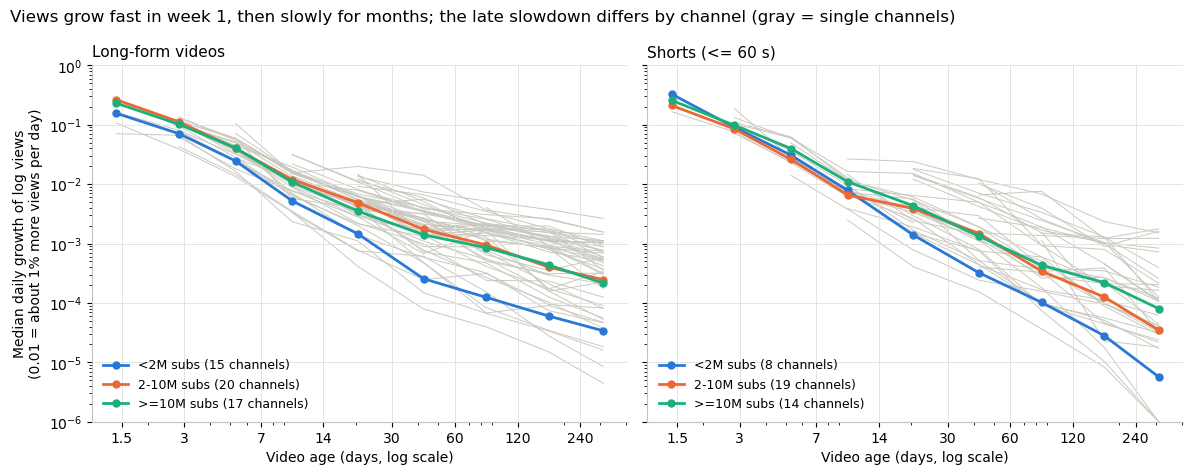

In [16]:
"""Figure 1: median daily growth rate by age, per format, one line per size tier; thin gray lines are single
channels (median of a channel's pairs in that age bin, bins with >= 10 pairs). Bin (0, 1] is left out."""
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e1e0d9",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7", "font.size": 10})
df_plot_pairs = df_pairs[df_pairs["mid_age"] > 1].copy()
df_plot_pairs["age_bin"] = pd.cut(df_plot_pairs["mid_age"], RATE_BINS[1:])
bin_centers = {interval: np.sqrt(interval.left * interval.right) for interval in df_plot_pairs["age_bin"].cat.categories}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, fmt, fmt_title in [[axes[0], "long", "Long-form videos"], [axes[1], "short", "Shorts (<= 60 s)"]]:
    df_fmt_pairs = df_plot_pairs[df_plot_pairs["format"] == fmt]
    df_channel_rate = df_fmt_pairs.groupby(["channel_id", "age_bin"], observed=True)["r"].agg(["median", "size"]).reset_index()
    df_channel_rate = df_channel_rate[df_channel_rate["size"] >= 10]
    for channel_id, df_one in df_channel_rate.groupby("channel_id"):
        ax.plot(df_one["age_bin"].map(bin_centers), df_one["median"].clip(lower=1e-6), color="#c9c8c0", linewidth=0.7, zorder=1)
    for tier in TIER_LABELS:
        df_tier_rate = df_fmt_pairs[df_fmt_pairs["tier"] == tier].groupby("age_bin", observed=True)["r"].median()
        n_channels = df_fmt_pairs[df_fmt_pairs["tier"] == tier]["channel_id"].nunique()
        ax.plot(df_tier_rate.index.map(bin_centers), df_tier_rate.values, color=COLORS[tier], linewidth=2, marker="o",
                markersize=5, label=f"{tier} ({n_channels} channels)", zorder=3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylim(1e-6, 1)
    ax.set_title(fmt_title, loc="left", fontsize=11)
    ax.set_xlabel("Video age (days, log scale)")
    ax.set_xticks([1.5, 3, 7, 14, 30, 60, 120, 240])
    ax.set_xticklabels(["1.5", "3", "7", "14", "30", "60", "120", "240"])
    ax.legend(frameon=False, fontsize=9, loc="lower left")
axes[0].set_ylabel("Median daily growth of log views\n(0.01 = about 1% more views per day)")
fig.suptitle("Views grow fast in week 1, then slowly for months; the late slowdown differs by channel (gray = single channels)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_growth_rate.png", dpi=150, bbox_inches="tight")
plt.show()

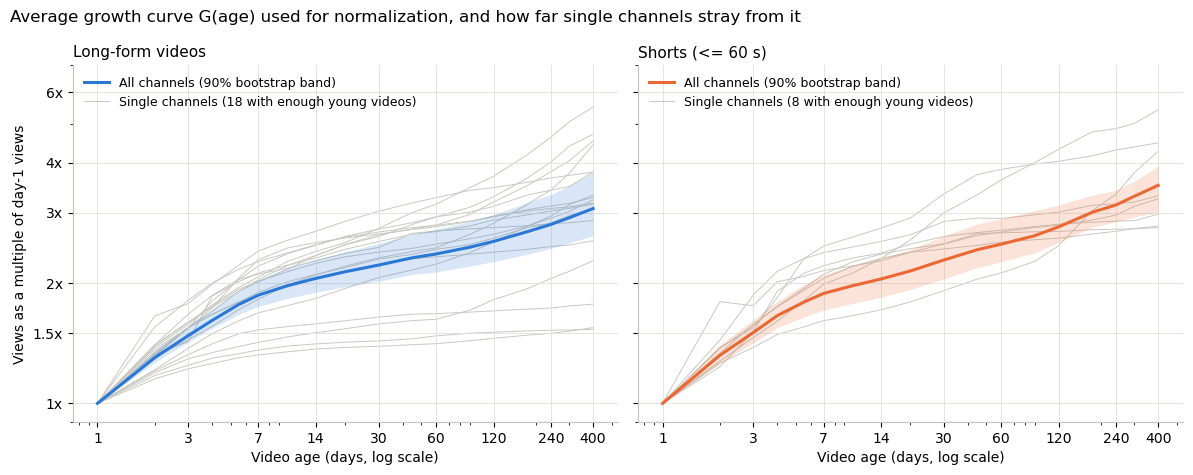

In [17]:
"""Figure 2: cumulative growth since day 1 (views as a multiple of day-1 views), average curve with 90% channel
bootstrap band, and per-channel curves (thin gray, channels with every knot supported)."""
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
for ax, fmt, fmt_title in [[axes[0], "long", "Long-form videos"], [axes[1], "short", "Shorts (<= 60 s)"]]:
    n_shown = 0
    for channel_id, channel_rows in df_pairs.iloc[format_rows[fmt]].groupby("channel_id").indices.items():
        G_channel = fit_curve(format_rows[fmt][channel_rows], min_support=10)
        if np.isnan(G_channel).any():
            continue
        n_shown += 1
        ax.plot(KNOTS, np.exp(G_channel), color="#c9c8c0", linewidth=0.7, zorder=1)
    df_fmt_curve = df_curve[df_curve["format"] == fmt]
    ax.fill_between(KNOTS, np.exp(df_fmt_curve["ci_low"]), np.exp(df_fmt_curve["ci_high"]), color=COLORS[fmt], alpha=0.18, linewidth=0, zorder=2)
    ax.plot(KNOTS, np.exp(df_fmt_curve["cumulative_log_growth"]), color=COLORS[fmt], linewidth=2.2, zorder=3,
            label=f"All channels (90% bootstrap band)")
    ax.plot([], [], color="#c9c8c0", linewidth=0.7, label=f"Single channels ({n_shown} with enough young videos)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks([1, 3, 7, 14, 30, 60, 120, 240, 400])
    ax.set_xticklabels(["1", "3", "7", "14", "30", "60", "120", "240", "400"])
    ax.set_yticks([1, 1.5, 2, 3, 4, 6])
    ax.set_yticklabels(["1x", "1.5x", "2x", "3x", "4x", "6x"])
    ax.set_ylim(0.9, 7)
    ax.set_title(fmt_title, loc="left", fontsize=11)
    ax.set_xlabel("Video age (days, log scale)")
    ax.legend(frameon=False, fontsize=9, loc="upper left")
axes[0].set_ylabel("Views as a multiple of day-1 views")
fig.suptitle("Average growth curve G(age) used for normalization, and how far single channels stray from it",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_curve.png", dpi=150, bbox_inches="tight")
plt.show()

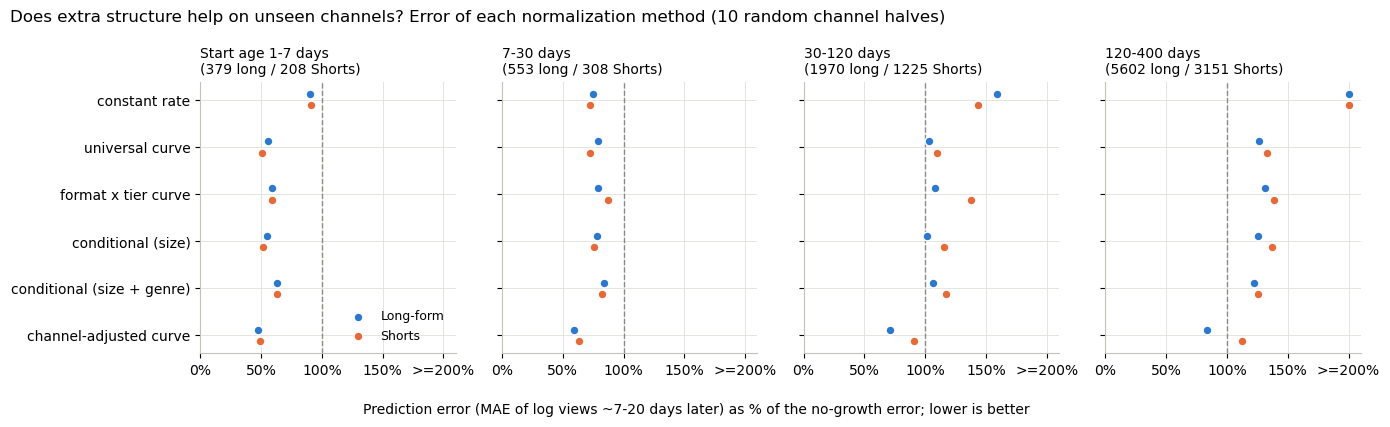

In [18]:
"""Figure 3: forward-prediction error on held-out channels as a share of the no-growth error, per age band of
the starting snapshot. Lower is better; 100% = no better than assuming no growth."""
PLOT_METHODS = METHODS[1:]
BAND_ORDER = ["[1, 7)", "[7, 30)", "[30, 120)", "[120, 400)"]
BAND_TITLES = {"[1, 7)": "Start age 1-7 days", "[7, 30)": "7-30 days", "[30, 120)": "30-120 days", "[120, 400)": "120-400 days"}
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2), sharey=True)
for ax, band in zip(axes, BAND_ORDER):
    for fmt, offset, fmt_label in [["long", -0.12, "Long-form"], ["short", 0.12, "Shorts"]]:
        ratio = df_mae.loc[(fmt, band), PLOT_METHODS] / df_mae.loc[(fmt, band), "no growth"] * 100
        ax.scatter(ratio.clip(upper=200).values, np.arange(len(PLOT_METHODS)) + offset, color=COLORS[fmt], s=40, zorder=3,
                   label=fmt_label, edgecolor="white", linewidth=1)
    ax.axvline(100, color="#8a8a85", linewidth=1, linestyle="--", zorder=2)
    n_long = int(df_mae.loc[("long", band), "videos"])
    n_short = int(df_mae.loc[("short", band), "videos"])
    ax.set_title(f"{BAND_TITLES[band]}\n({n_long} long / {n_short} Shorts)", loc="left", fontsize=10)
    ax.set_xlim(0, 210)
    ax.set_xticks([0, 50, 100, 150, 200])
    ax.set_xticklabels(["0%", "50%", "100%", "150%", ">=200%"])
axes[0].set_yticks(np.arange(len(PLOT_METHODS)))
axes[0].set_yticklabels(PLOT_METHODS)
axes[0].invert_yaxis()
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
fig.supxlabel("Prediction error (MAE of log views ~7-20 days later) as % of the no-growth error; lower is better", fontsize=10)
fig.suptitle(f"Does extra structure help on unseen channels? Error of each normalization method ({N_SPLITS} random channel halves)",
             x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_method_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

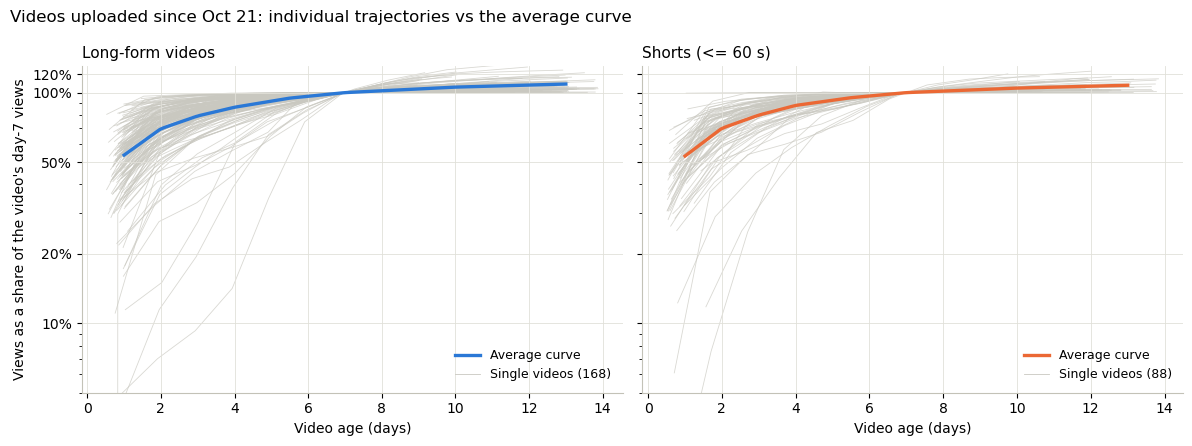

In [19]:
"""Figure 4: young videos' own trajectories relative to their day-7 views, against the average curve.
If every video mirrored the curve, all lines would sit on it."""
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
young_lv7 = df_young.set_index("video_id")["lv_day7"].dropna()
for ax, fmt, fmt_title in [[axes[0], "long", "Long-form videos"], [axes[1], "short", "Shorts (<= 60 s)"]]:
    df_traj = df_young_panel[(df_young_panel["format"] == fmt) & df_young_panel["video_id"].isin(young_lv7.index) & (df_young_panel["age_days"] >= 0.5)]
    for video_id, df_video in df_traj.groupby("video_id"):
        ax.plot(df_video["age_days"], np.exp(df_video["lv"] - young_lv7[video_id]), color="#c9c8c0", linewidth=0.6, alpha=0.7, zorder=1)
    age_grid = np.linspace(1, 13, 100)
    ax.plot(age_grid, np.exp(G_at(curves[fmt], age_grid) - G_at(curves[fmt], 7)), color=COLORS[fmt], linewidth=2.4, zorder=3,
            label="Average curve")
    ax.plot([], [], color="#c9c8c0", linewidth=0.6, label=f"Single videos ({df_traj['video_id'].nunique()})")
    ax.set_yscale("log")
    ax.set_yticks([0.1, 0.2, 0.5, 1, 1.2])
    ax.set_yticklabels(["10%", "20%", "50%", "100%", "120%"])
    ax.set_ylim(0.05, 1.3)
    ax.set_title(fmt_title, loc="left", fontsize=11)
    ax.set_xlabel("Video age (days)")
    ax.legend(frameon=False, fontsize=9, loc="lower right")
axes[0].set_ylabel("Views as a share of the video's day-7 views")
fig.suptitle("Videos uploaded since Oct 21: individual trajectories vs the average curve", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/age_young_trajectories.png", dpi=150, bbox_inches="tight")
plt.show()

## Findings

Snapshots 2026-10-15 (seed) and 2026-10-21 to 2026-11-04; 13,718 videos, 52 channels, 187,955 consecutive daily pairs.

- **Panel quality is good.** One pull per day since 10-21 (spacing 0.78-1.14 days, median 1.00; starts drift with GitHub cron), no missing days for any video, no unavailable videos. View counts drop in 0.27% of daily pairs (median drop 0.00003 log units, YouTube spam correction); likes drop in 9% (rounding of displayed likes), so the like curve is noisier. The 10-15 seed ran per channel over 15 hours (age is computed per row, so it is usable) and is 6.6 days before the next pull. 3 scheduled streams/premieres sat at 0 views for days and were excluded from growth pairs.
- **Growth vs age (mean curve, anchored at day 1).** Long-form: views x1.87 from day 1 to 7, x1.19 more by day 30, x1.39 more from day 30 to day 400. Shorts: x1.88, x1.21, x1.54. Long and Shorts are nearly identical through day 30; Shorts keep growing more afterwards (mean), but their median late growth is lower: a minority of old Shorts get resurfaced. Likes grow less (x1.65 day 1 to 7). Channel bootstrap 90% interval for the day-30 adjustment of a 400-day-old video: -0.24 to -0.44 log units (long), -0.23 to -0.61 (Shorts).
- **Young videos mirror the curve fairly well.** Of day-13 views, a median of 53% / 46% (long / Shorts) is reached on day 1, 82% / 78% by day 3 and 96% / 95% by day 7 (28 / 11 videos so far). Early rank predicts later rank: Spearman day 1 vs day 7 = 0.95 (163 long) / 0.98 (85 Shorts), and later growth is nearly unrelated to early views (rho 0.03-0.10), consistent with growth being multiplicative (a shift in log views).
- **Heterogeneity.** Video-level log growth rate over the 2-week window: age alone explains 31% of the variance (55% under 30 days, 14% over 30 days). Format adds ~1 point. Size tier and genre raise in-sample R2 (to 47%) but lower it on held-out channels (25% -> 12%): they mostly encode which channels are in the sample. Channel identity adds most in sample (58%; 49% for old videos) and holds on held-out videos of the same channels (58%). Small channels (<2M) decay visibly faster after day 7 (Figure 1), but only 15 long / 8 Shorts channels are in that tier.
- **Forward prediction on held-out channels** (10 random channel halves; MAE of log views 7-20 days later). From a start age of 1-7 days the universal curve halves the error of "no growth" (long 0.39 -> 0.22, Shorts 0.39 -> 0.20); format x tier curves (0.23 / 0.23) and the conditional regressions (size: 0.22 / 0.20; size + genre: 0.24 / 0.25) do not beat it; a channel adjustment from the channel's other videos helps a little (0.19 / 0.19). At 7-30 days the curve cuts error by ~20-28% and the channel adjustment by ~36-41%. Beyond 30 days, growth in 3 weeks is ~1% and the mean curve has higher MAE than "no growth" (it is unbiased, bias < 0.006, but the mean is pulled up by a few resurging videos); only the channel adjustment beats no growth there (long).
- **Size of the problem.** On 11-04 log views have SD 1.85 (long) / 2.40 (Shorts) across videos and ~0.95 within a channel. The full age correction from day 1 to day 400 is ~1.1-1.3 log units, so age matters for raw comparisons, while the error the curve leaves for young videos (~0.2) is small next to the within-channel spread.
- **Direct day-7 alternative.** 256 videos uploaded after 10-21 already have an observed day-7 value (230 tagged); ~38 uploads/day (~35 tagged/day) join, so ~1,000 more per month.
- **Not validated:** the curve beyond ~3 weeks per video. G between day 30 and 400 is stitched from different cohorts of videos observed in one 2-week calendar window (assumes the age pattern is stable across upload dates and seasons). Channel adjustment k is estimated on the same calendar dates as the videos it is scored on, which may flatter it.
- **Literature:** Szabo & Huberman (CACM 2010) report that log early popularity predicts log later popularity and that YouTube needs about 10 days of tracking to forecast 30-day views as well as Digg does from 2 hours; our day 1 vs day 7 rank correlation of 0.95-0.98 is in line with that.

**Recipe:** log V_ref = log(1+V(a)) + G_format(a_ref) - G_format(a), using `data/analysis/age_curve.csv` (interpolate linearly in age), a_ref = 7 days (within observed trajectories) for videos aged >= 1 day; use a_ref = 30 only with the caveat above. Use only age and format (optionally the channel's typical decay from its other videos), never the video's own early growth, which would absorb the trait effects being estimated.